In [1]:
import pandas as pd

In [2]:
import numpy as np

In [4]:
df = pd.read_excel("/content/Dataset.xlsx")
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,NaN,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,NaN,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,NaN,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,NaN,31.37


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          19 non-null     int64  
 1   Name          19 non-null     object 
 2   Platform      19 non-null     object 
 3   Year          19 non-null     int64  
 4   Genre         19 non-null     object 
 5   Publisher     19 non-null     object 
 6   NA_Sales      19 non-null     float64
 7   EU_Sales      19 non-null     float64
 8   JP_Sales      19 non-null     float64
 9   Other_Sales   19 non-null     float64
 10  Global_Sales  19 non-null     float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.8+ KB


In [18]:
df.shape

(19, 11)

In [10]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000
mean,10.000000,2002.105263,14.302895,7.618421,3.760789,2.874737,30.231053
std,5.627314,8.924963,8.285388,6.011926,2.590003,2.563722,13.796933
min,1.000000,1984.000000,7.010000,0.400000,0.240000,0.470000,20.610000
25%,5.500000,1997.500000,9.260000,4.345000,2.230000,1.730000,22.910000
50%,10.000000,2006.000000,11.325000,7.570000,3.685000,2.260000,28.310000
75%,14.500000,2008.500000,15.360000,9.045000,4.460000,2.930000,30.690000
max,19.000000,2013.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [19]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')

In [5]:
df.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,0
Genre,0
Publisher,0
NA_Sales,3
EU_Sales,2
JP_Sales,1
Other_Sales,2


In [20]:
df.dtypes

,0
Rank,int64
Name,object
Platform,object
Year,int64
Genre,object
Publisher,object
NA_Sales,float64
EU_Sales,float64
JP_Sales,float64
Other_Sales,float64


In [8]:
df[df.select_dtypes(include="number").columns] = df.select_dtypes(include="number").fillna(df.select_dtypes(include="number").median())

In [21]:
sales_columns = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]

In [22]:
df[sales_columns] = df[sales_columns].fillna(df[sales_columns].median())

In [23]:
print(df.isnull().sum())

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# **Global Sales of selected games.**

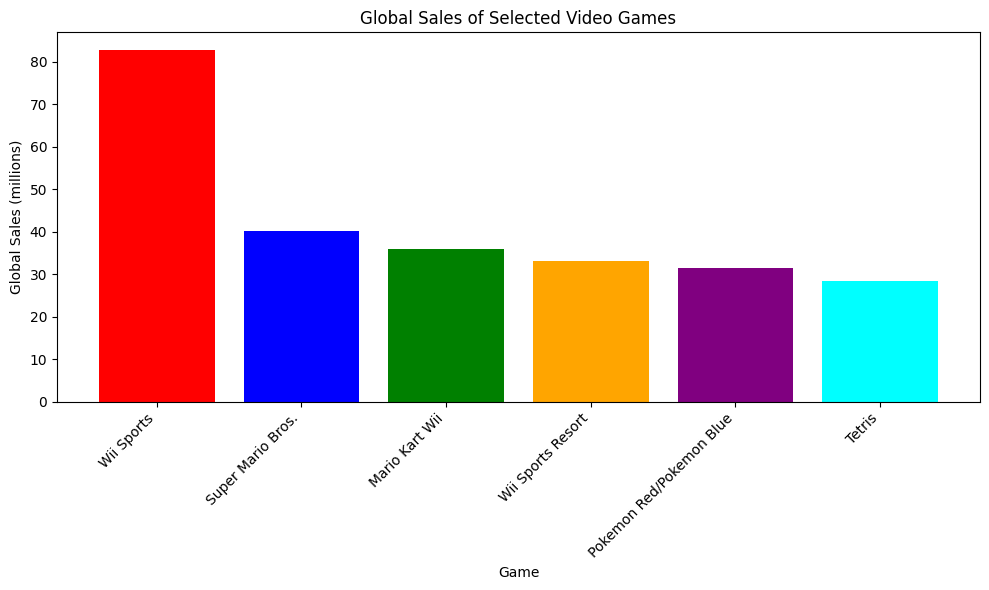

In [13]:
selected_games = df.head(6)

plt.figure(figsize=(10, 6))

plt.bar(
    selected_games["Name"],
    selected_games["Global_Sales"],
    color=["red", "blue", "green", "orange", "purple", "cyan"]
)

plt.title("Global Sales of Selected Video Games")
plt.xlabel("Game")
plt.ylabel("Global Sales (millions)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# **Average global sales across years**

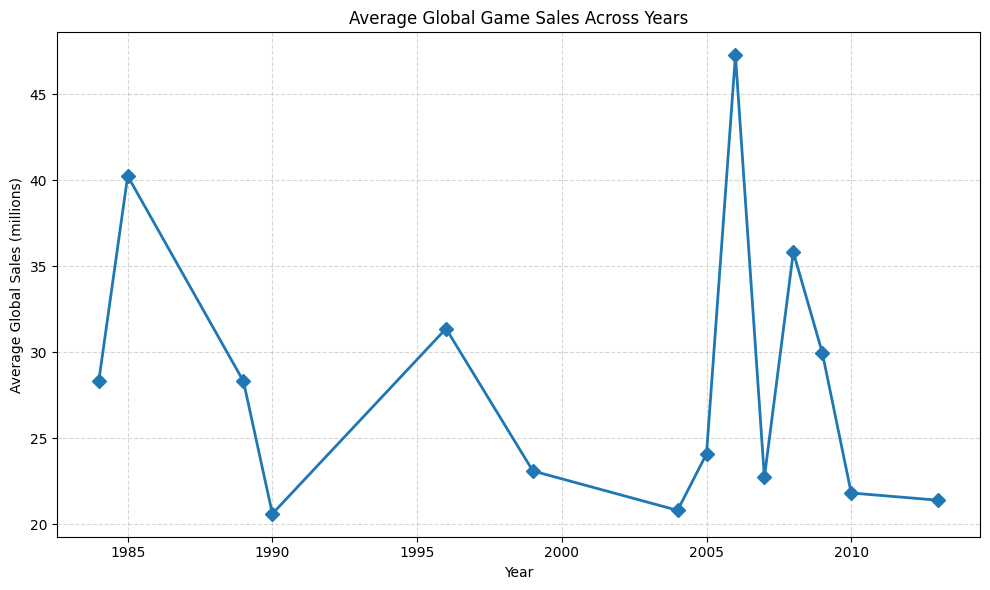

In [14]:
year_sales = df.groupby("Year")["Global_Sales"].mean()

plt.figure(figsize=(10, 6))

plt.plot(
    year_sales.index,
    year_sales.values,
    marker="D",
    linestyle="-",
    linewidth=2,
    markersize=7
)

plt.title("Average Global Game Sales Across Years")
plt.xlabel("Year")
plt.ylabel("Average Global Sales (millions)")

plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# North American Sales and Global **Sales**

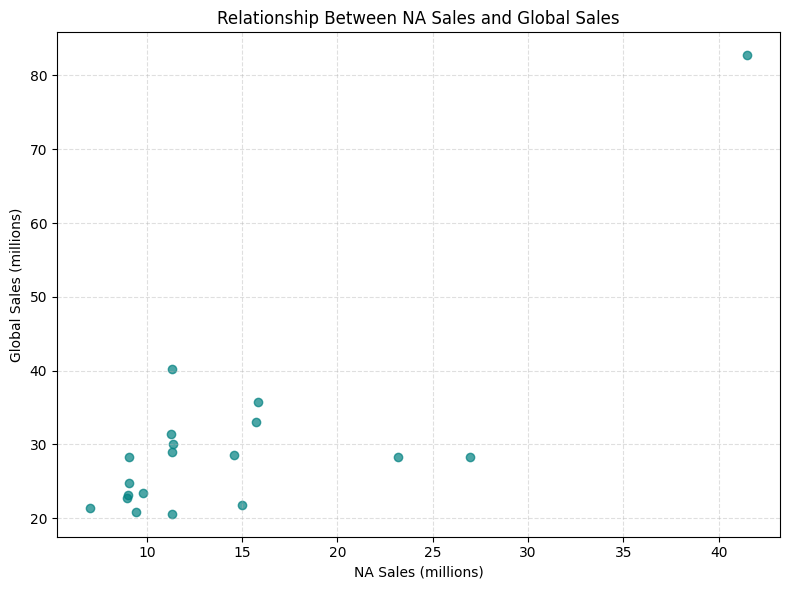

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["NA_Sales"],
    df["Global_Sales"],
    color="teal",
    alpha=0.7
)

plt.title("Relationship Between NA Sales and Global Sales")
plt.xlabel("NA Sales (millions)")
plt.ylabel("Global Sales (millions)")

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# **NA Sales and Global Sales**

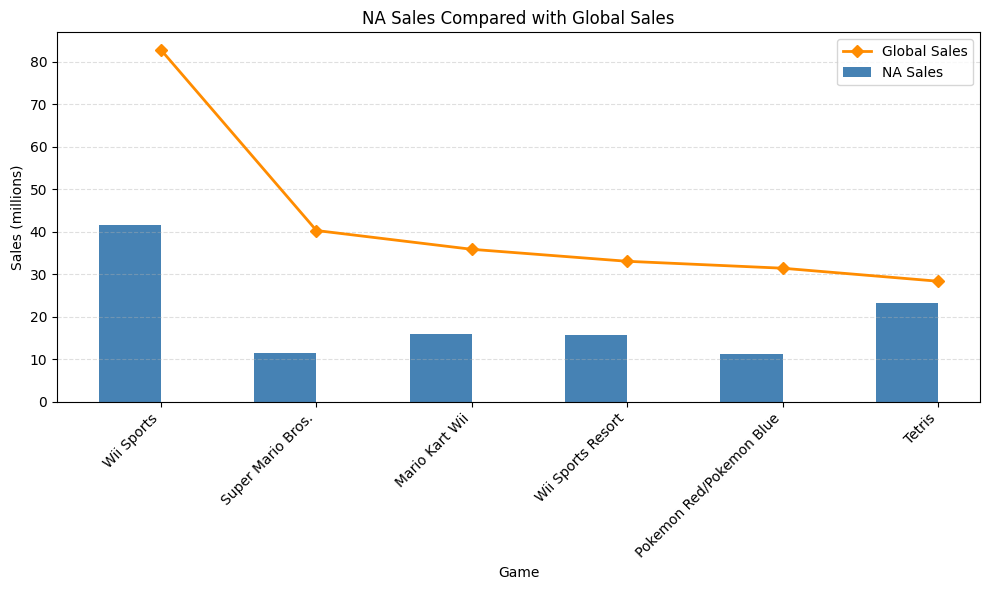

In [16]:
selected_games = df.head(6)

x = range(len(selected_games))

plt.figure(figsize=(10, 6))

plt.bar(
    [i - 0.2 for i in x],
    selected_games["NA_Sales"],
    width=0.4,
    label="NA Sales",
    color="steelblue"
)

plt.plot(
    x,
    selected_games["Global_Sales"],
    marker="D",
    linewidth=2,
    label="Global Sales",
    color="darkorange"
)

plt.xticks(
    x,
    selected_games["Name"],
    rotation=45,
    ha="right"
)

plt.title("NA Sales Compared with Global Sales")
plt.xlabel("Game")
plt.ylabel("Sales (millions)")

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

# **Data Story**
The dataset contains 19 highly ranked video games released between 1984 and 2013. It includes information about platforms, genres, publishers and sales across North America, Europe, Japan and other regions. Before analysing the data, I checked for missing values and replaced missing numerical sales values with the median.

The results show a large difference between the highest-selling games and the rest. Wii Sports is the strongest game in the dataset, with 82.74 million global sales. It also has particularly strong sales in North America and Europe. Nintendo dominates the dataset, with 16 of the 19 games published by the company, and the Wii is the most common platform.

The scatter plot shows a clear positive relationship between North American and global sales. This suggests that strong performance in North America is generally associated with strong worldwide performance. However, regional preferences are also visible. Pokémon games perform particularly well in Japan, while several Wii and Nintendo games have strong sales across multiple regions.

Based on these findings, the company should continue targeting the North American market while adapting marketing and game content to regional preferences, particularly in Japan and Europe.
